# Variational Classifier — Bars and Stripes

Misma estructura que `Variational_Classifier_Iris`, adaptado a clasificación binaria Bars and Stripes con PCA→4 qubits.


## Librerias


In [1]:
# 1. Import all libraries
import json
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as np
from pennylane.data import Dataset
from pennylane.optimize import NesterovMomentumOptimizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

np.random.seed(123)


## Data

Imágenes oficiales PennyLane (`4×4` → 16 features). Carga lazy del `.h5`.


In [2]:
DATASET_URL = (
    "https://datasets.cloud.pennylane.ai/datasets/h5/"
    "other/BarsAndStripes/BarsAndStripes_BarsAndStripes.h5"
)
IMAGE_SIZE = "4"  # 4x4 pixels -> 16 features


def resolve_dataset_path() -> Path:
    """Busca el .h5 en caches locales tipicos de PennyLane."""
    candidates = []
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        candidates.append(
            base / "datasets" / "other" / "BarsAndStripes" / "BarsAndStripes_BarsAndStripes.h5"
        )
    for path in candidates:
        if path.is_file():
            return path
    return candidates[0]


def ensure_bars_and_stripes(path: Path | None = None) -> Path:
    path = resolve_dataset_path() if path is None else Path(path)
    if path.is_file():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading PennyLane bars-and-stripes -> {path} (one-time, ~750MB)")
    urllib.request.urlretrieve(DATASET_URL, path)
    return path


def load_bars_and_stripes(image_size: str = IMAGE_SIZE):
    path = ensure_bars_and_stripes()
    ds = Dataset.open(path, "r")
    try:
        X_train = np.asarray(ds.train[image_size]["inputs"], dtype=float)
        y_train = np.asarray(ds.train[image_size]["labels"], dtype=float)
        X_test = np.asarray(ds.test[image_size]["inputs"], dtype=float)
        y_test = np.asarray(ds.test[image_size]["labels"], dtype=float)
    finally:
        ds.close()
    return X_train, y_train, X_test, y_test


print("Loading PennyLane 'bars-and-stripes' (image_size=4)...")
X_train_official, y_train_official, X_test_official, y_test_official = load_bars_and_stripes(IMAGE_SIZE)
print(
    f"Official splits -> train: {X_train_official.shape}, test: {X_test_official.shape}"
)
print("Label values (train):", np.unique(y_train_official, return_counts=True))


Loading PennyLane 'bars-and-stripes' (image_size=4)...
Official splits -> train: (1000, 16), test: (200, 16)
Label values (train): (tensor([-1.,  1.], requires_grad=True), array([514, 486]))


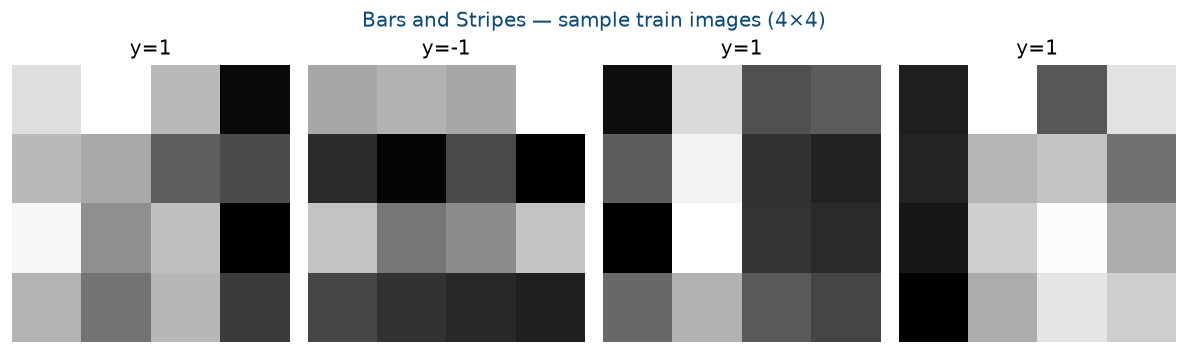

In [3]:
# Preview: first samples as 4x4 images + label
fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=120)
for i, ax in enumerate(axs):
    ax.imshow(X_train_official[i].reshape(4, 4), cmap="gray")
    ax.set_title(f"y={int(y_train_official[i])}")
    ax.axis("off")
fig.suptitle("Bars and Stripes — sample train images (4×4)", color="#0E4A75")
plt.tight_layout()
plt.show()


## Data Preparation

Protocolo Iris + PCA→4.


In [4]:
n_qubits = 4
n_classes = 2

X_all = np.concatenate([X_train_official, X_test_official], axis=0)
y_all = np.concatenate([y_train_official, y_test_official], axis=0)
y_all = np.where(np.array(y_all) <= 0, 0, 1).astype(int)

print(f"Combined dataset: n={len(X_all)}, features={X_all.shape[1]}, classes={np.unique(y_all, return_counts=True)}")

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    np.array(X_all, dtype=float),
    np.array(y_all, dtype=int),
    test_size=0.4,
    random_state=123,
    stratify=y_all,
)
print(f"Custom Dataset Loaded: Train={len(X_train_raw)}, Test={len(X_test_raw)}")

pca = PCA(n_components=n_qubits, random_state=123)
X_train_pca = pca.fit_transform(X_train_raw)
X_test_pca = pca.transform(X_test_raw)
print(f"PCA explained variance ratio sum: {pca.explained_variance_ratio_.sum():.4f}")

minmax = MinMaxScaler(feature_range=(0, np.pi))
X_train = minmax.fit_transform(np.array(X_train_pca, dtype=float))
X_test = np.clip(minmax.transform(np.array(X_test_pca, dtype=float)), 0, np.pi)
y_train = np.array(y_train)
y_test = np.array(y_test)
n_features = X_train.shape[1]
print(f"Final shapes -> Train: {X_train.shape}, Test: {X_test.shape}")


Combined dataset: n=1200, features=16, classes=(tensor([0, 1], requires_grad=True), array([625, 575]))
Custom Dataset Loaded: Train=720, Test=480
PCA explained variance ratio sum: 0.5753
Final shapes -> Train: (720, 4), Test: (480, 4)


## Variational Classifier


In [5]:
dev = qml.device("default.qubit")


### Variational Data Prep


In [6]:
# Use the stratified train split prepared above
X = np.array(X_train, dtype=float)
y = np.array(y_train, dtype=int)


In [7]:
def layer(layer_weights):
    for wire in range(n_qubits):
        qml.Rot(*layer_weights[wire], wires=wire)
    for wires in ([0, 1], [1, 2], [2, 3], [3, 0]):
        qml.CNOT(wires=wires)


In [8]:
def state_preparation(x):
    for i in range(n_qubits):
        qml.RY(x[i], wires=i)


In [9]:
@qml.qnode(dev)
def circuit(weights, x):
    state_preparation(x)
    for layer_weights in weights:
        layer(layer_weights)
    # Binary: 2 expectation values
    return [
        qml.expval(qml.PauliZ(0)),
        qml.expval(qml.PauliZ(1)),
    ]

def variational_classifier(weights, bias, x):
    out = qml.math.stack(circuit(weights, x))
    return out + bias

def cost(weights, bias, X, Y):
    predictions = qml.math.stack(
        [variational_classifier(weights, bias, x) for x in X]
    )
    Y = np.array(Y, dtype=int)
    targets = np.eye(n_classes)[Y]
    return qml.math.mean((predictions - targets) ** 2)


In [ ]:
# --- Tiempo de entrenamiento ---
np.random.seed(123)
weights = 0.01 * np.random.randn(2, n_qubits, 3, requires_grad=True)
bias = np.zeros(n_classes, requires_grad=True)
opt = NesterovMomentumOptimizer(0.1)
batch_size = 5

start = time.time()
for it in range(100):
    batch_index = np.random.randint(0, len(X), (batch_size,))
    X_batch = X[batch_index]
    Y_batch = y[batch_index]
    weights, bias = opt.step(cost, weights, bias, X=X_batch, Y=Y_batch)

    predictions = [np.argmax(variational_classifier(weights, bias, x)) for x in X]
    current_cost = cost(weights, bias, X, y)
    acc = np.mean(np.array(predictions) == np.array(y))
    print(f"Iter: {it+1:4d} | Cost: {current_cost:0.7f} | Accuracy: {acc:0.7f}")
train_time = time.time() - start
print(f"\nTraining time: {train_time:.4f} s")


Iter:    1 | Cost: 0.4704294 | Accuracy: 0.5166667
Iter:    2 | Cost: 0.3932372 | Accuracy: 0.4430556
Iter:    3 | Cost: 0.3224671 | Accuracy: 0.4583333
Iter:    4 | Cost: 0.2788601 | Accuracy: 0.4805556
Iter:    5 | Cost: 0.2607770 | Accuracy: 0.4541667
Iter:    6 | Cost: 0.2625501 | Accuracy: 0.4444444
Iter:    7 | Cost: 0.2759674 | Accuracy: 0.5305556
Iter:    8 | Cost: 0.2877972 | Accuracy: 0.5180556
Iter:    9 | Cost: 0.2918296 | Accuracy: 0.4694444
Iter:   10 | Cost: 0.2896836 | Accuracy: 0.4819444
Iter:   11 | Cost: 0.2861546 | Accuracy: 0.5138889
Iter:   12 | Cost: 0.2856937 | Accuracy: 0.5236111
Iter:   13 | Cost: 0.2984162 | Accuracy: 0.5250000
Iter:   14 | Cost: 0.2939070 | Accuracy: 0.5250000
Iter:   15 | Cost: 0.2974912 | Accuracy: 0.5250000


In [ ]:
# Predicción + métricas train vs test
def predict(weights, bias, X_data):
    return np.array([
        np.argmax(variational_classifier(weights, bias, x))
        for x in X_data
    ])

def evaluate_split(weights, bias, X_data, y_data):
    preds = predict(weights, bias, X_data)
    y_true = np.array(y_data).astype(int)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, average="macro", zero_division=0)
    rec = recall_score(y_true, preds, average="macro", zero_division=0)
    f1 = f1_score(y_true, preds, average="macro", zero_division=0)
    return acc, prec, rec, f1, preds

start = time.time()
y_test_pred = predict(weights, bias, X_test)
infer_time = time.time() - start

vqc_acc_tr, vqc_prec_tr, vqc_rec_tr, vqc_f1_tr, _ = evaluate_split(weights, bias, X, y)
vqc_acc, vqc_prec, vqc_rec, vqc_f1, y_test_pred = evaluate_split(weights, bias, X_test, y_test)

print("\n=== Train vs Test ===")
print(
    f"VQC Train - Acc: {vqc_acc_tr:.4f} | Prec: {vqc_prec_tr:.4f} | Rec: {vqc_rec_tr:.4f} | "
    f"F1: {vqc_f1_tr:.4f}"
)
print(
    f"VQC Test  - Acc: {vqc_acc:.4f} | Prec: {vqc_prec:.4f} | Rec: {vqc_rec:.4f} | "
    f"F1: {vqc_f1:.4f}"
)
print(f"Inference time: {infer_time:.4f} s")
print(f"Training time:  {train_time:.4f} s")


In [ ]:
# Result Visualization (train vs test + paleta UNIR)
plt.rcParams.update({
    "font.sans-serif": ["Arial"],
    "axes.edgecolor": "#C0C0C8",
    "grid.color": "#C0C0C8",
    "grid.linestyle": "--",
})


train_color = "#0E4A75"
test_color = "#219BC3"
unir_gris = "#858591"

fig, axs = plt.subplots(1, 2, figsize=(14, 5), dpi=150)
fig.suptitle("Variational Classifier — Bars and Stripes", fontsize=18, y=1.02, color="#0E4A75")

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
train_vals = [vqc_acc_tr, vqc_prec_tr, vqc_rec_tr, vqc_f1_tr]
test_vals = [vqc_acc, vqc_prec, vqc_rec, vqc_f1]
x = np.arange(len(metrics))
width = 0.35

for i in range(len(metrics)):
    axs[0].bar(x[i] - width / 2, train_vals[i], width, color=train_color,
               label="Train" if i == 0 else "", zorder=3)
    axs[0].bar(x[i] + width / 2, test_vals[i], width, color=test_color,
               label="Test" if i == 0 else "", zorder=3)

axs[0].set_ylabel("Score")
axs[0].set_title("Train vs Test Metrics", color="#0E4A75")
axs[0].set_xticks(x)
axs[0].set_xticklabels(metrics)
axs[0].set_ylim(0, 1.35)
axs[0].legend(loc="upper right")
axs[0].grid(axis="y", zorder=0)

eff_labels = ["Training Time", "Inference Time"]
eff = [train_time, infer_time]
x_eff = np.arange(len(eff_labels))
axs[1].bar(x_eff, eff, 0.5, color="#219BC3", label="VQC", zorder=3)
axs[1].set_xticks(x_eff)
axs[1].set_xticklabels(eff_labels)
axs[1].set_ylabel("Time (s)")
axs[1].set_title("Computational Efficiency", color="#0E4A75")
max_time = max(eff)
axs[1].set_ylim(0, max_time * 1.35 if max_time > 0 else 1)
axs[1].legend(loc="upper right")
axs[1].grid(axis="y", zorder=0)
offset = max_time * 0.02 if max_time > 0 else 0.02
for i in range(2):
    axs[1].text(x_eff[i], eff[i] + offset, f"{eff[i]:.4f}s",
                ha="center", va="bottom", fontsize=9, color=unir_gris)

plt.tight_layout()
plt.show()


## Guardar resultados


In [ ]:
# Save metrics for QuantumClassification comparison
def resolve_metrics_dir() -> Path:
    """Guarda en Notebooks/QuantumClassification/metrics."""
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        quantum = base / "Notebooks" / "QuantumClassification"
        if quantum.is_dir():
            metrics_dir = quantum / "metrics"
            metrics_dir.mkdir(parents=True, exist_ok=True)
            return metrics_dir
    metrics_dir = Path.cwd().resolve() / "Notebooks" / "QuantumClassification" / "metrics"
    metrics_dir.mkdir(parents=True, exist_ok=True)
    return metrics_dir

metrics_dir = resolve_metrics_dir()

payload = {
    "model": "VQC",
    "family": "quantum",
    "protocol": {
        "dataset": "bars-and-stripes",
        "image_size": int(IMAGE_SIZE),
        "n_features": int(n_features),
        "test_size": 0.4,
        "random_state": 123,
        "stratify": True,
        "scaler": "MinMaxScaler[0, pi]",
        "labels": "mapped {-1,1}->{0,1}",
        "pca": "PCA(n_components=4)",
        "n_qubits": 4,
    },
    "train": {
        "accuracy": float(vqc_acc_tr),
        "precision": float(vqc_prec_tr),
        "recall": float(vqc_rec_tr),
        "f1": float(vqc_f1_tr),
        "auc": None,
    },
    "test": {
        "accuracy": float(vqc_acc),
        "precision": float(vqc_prec),
        "recall": float(vqc_rec),
        "f1": float(vqc_f1),
        "auc": None,
    },
    "train_time_s": float(train_time),
    "inference_time_s": float(infer_time),
}

out = metrics_dir / "vqc_bs.json"
out.write_text(json.dumps(payload, indent=2))
print("Saved:", out)
